<a href="https://colab.research.google.com/github/nutangaonkar/CSL701-CE09-Machine-Learning-Lab/blob/main/Experiments/Experiment_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 10


Student Name : Nutan Nandkishor Gaonkar

Batch : CE01


Roll Number : CE09



### **Aim**

To implement DBSCAN clustering using Python for customer segmentation on the Mall Customer Segmentation dataset and identify arbitrary-shaped clusters along with spatial outliers (noise).

## Objectives

1. To understand the principles of Density-Based Spatial Clustering of Applications with Noise (DBSCAN).
2. To implement DBSCAN clustering using Python.3. To preprocess and feature-scale tabular customer data using StandardScaler.
4. To determine optimal hyperparameters ($\varepsilon$ and $min\_samples$) using $k$-distance graph analysis.
5. To identify core points, border points, and spatial outliers (noise points denoted by label $-1$).
6. To evaluate clustering performance using metrics like Silhouette Score.

# Relevant Theory

###DBSCAN (Density-Based Spatial Clustering of Applications with Noise)
DBSCAN is an unsupervised non-parametric clustering algorithm that groups data points based on local density estimations. Unlike centroid-based algorithms (e.g., K-Means), DBSCAN can discover arbitrary-shaped clusters and automatically isolate noisy data points without requiring the user to specify the total number of clusters in advance.

Core Concepts and Parameters:

1. $\varepsilon$ (Epsilon): The maximum radius of the neighborhood around a given data point $x$.
2. $min\_samples$ (MinPts): The minimum number of points within the $\varepsilon$-neighborhood required to form a dense region.

Point ClassificationsCore Point:
* A point that has at least $min\_samples$ within its $\varepsilon$-neighborhood.
* Border Point: A point that is within the $\varepsilon$-neighborhood of a Core Point but has fewer than $min\_samples$ in its own neighborhood.
* Noise Point (Outlier): A point that is neither a Core Point nor a Border Point. Noise points are assigned a cluster label of $-1$.

###Dataset Information
Get the Mall Customer Segmentation dataset from Kaggle using the following link:
https://www.kaggle.com/datasets/vjchoudhary7/customer-segmentation-tutorial-in-python

The dataset contains spending patterns and demographic attributes of mall customers:

* CustomerID: Unique identifier for each customer.

* Gender: Male or Female.

* Age: Age of the customer.

* Annual Income (k$): Annual income of the customer in thousands of dollars.

* Spending Score (1-100): Score assigned based on customer behavior and purchasing patterns.

For clustering, we will use: Annual Income (k$) and Spending Score (1-100).

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Mall Customer Segmentation dataset (Mall_Customers.csv).
---

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score



from google.colab import files

uploaded = files.upload()

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print(df.head())




Saving Mall_Customers.csv to Mall_Customers.csv
Dataset loaded successfully!
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


# Task 2: Feature Selection and Standardization

* Select target features (Annual Income ($k$) and Spending Score (1-100)).
* Scale features using Standard Scaler to bring feature dimensions to a comparable range ($\mu=0, \sigma=1$), which is crucial for distance-based neighborhood computations.

In [ ]:

# Task 2: Feature Selection and Standardization

# Select Annual Income and Spending Score
X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

print("Selected Features:")
print(X.head())



# Standardize the selected features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("\nFirst five standardized rows:")
print(X_scaled[:5])

# Verify mean and standard deviation
print("\nMean of standardized features:")
print(X_scaled.mean(axis=0))

print("\nStandard deviation of standardized features:")
print(X_scaled.std(axis=0))


Selected Features:
   Annual Income (k$)  Spending Score (1-100)
0                  15                      39
1                  15                      81
2                  16                       6
3                  16                      77
4                  17                      40
(200, 6)

First five standardized rows:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]

Mean of standardized features:
[-2.13162821e-16 -1.46549439e-16]

Standard deviation of standardized features:
[1. 1.]


# Task 3: Hyperparameter Selection via $k$-Distance Graph

* Compute Nearest Neighbors using NearestNeighbors ($k = min\_samples$).
* Plot sorted $k$-distances to locate the "elbow point," which indicates the optimal value for $\varepsilon$ (Epsilon).

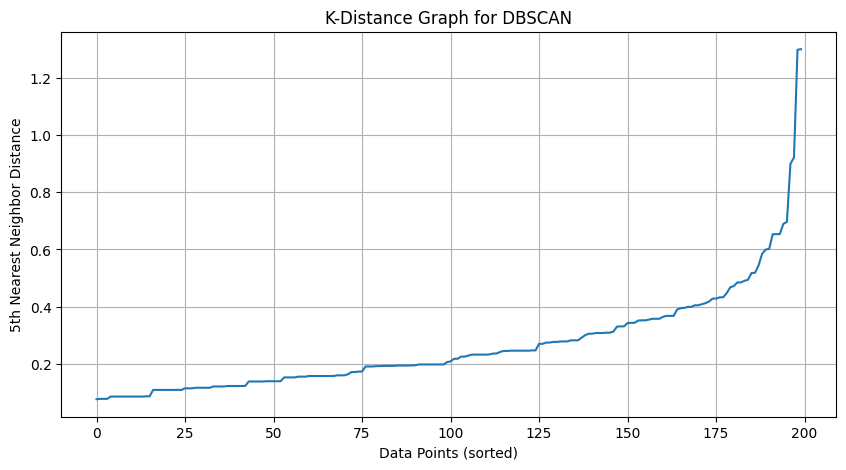

In [ ]:

# Task 3: Hyperparameter Selection via k-Distance Graph

# Set min_samples
min_samples = 5

# Compute nearest neighbors
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)

distances, indices = neighbors.kneighbors(X_scaled)

# Extract the distance to the 5th nearest neighbor
k_distances = np.sort(distances[:, min_samples - 1])

# Plot the k-distance graph
plt.figure(figsize=(10, 5))
plt.plot(k_distances)

plt.xlabel("Data Points (sorted)")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Graph for DBSCAN")
plt.grid(True)
plt.show()


# Task 4: Implement DBSCAN Clustering

* Instantiate sklearn.cluster.DBSCAN with the identified $\varepsilon$ and $min\_samples$.
* Fit the model on scaled data to generate cluster assignments and noise labels ($-1$).

Cluster counts:
Cluster
-1      8
 0    157
 1     35
Name: count, dtype: int64


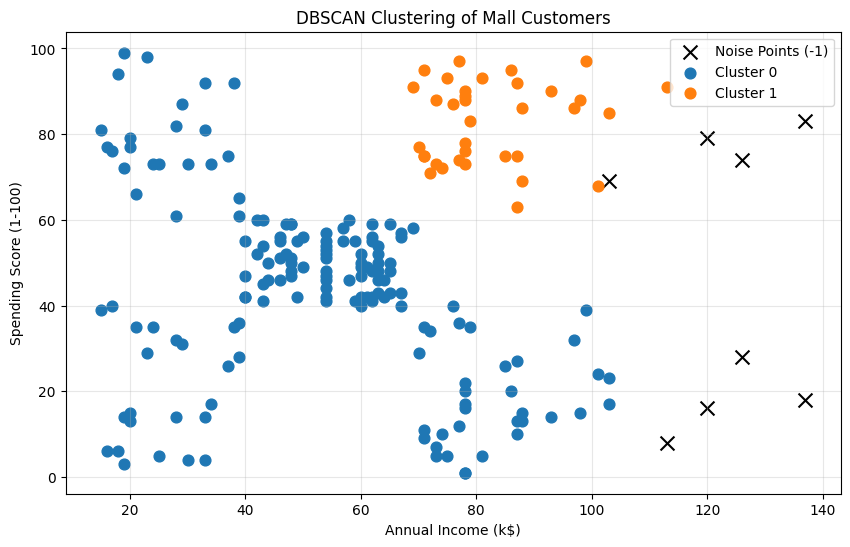

In [ ]:

# Task 4: DBSCAN Clustering with Visualization

eps_value = 0.5
min_samples = 5

# Fit DBSCAN on scaled data
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
labels = dbscan.fit_predict(X_scaled)

# Store cluster labels
df['Cluster'] = labels

# Print cluster counts
print("Cluster counts:")
print(df['Cluster'].value_counts().sort_index())

# Visualize clusters
plt.figure(figsize=(10, 6))

# Plot normal clusters
for cluster in sorted(set(labels)):
    points = df[df['Cluster'] == cluster]

    if cluster == -1:
        plt.scatter(
            points['Annual Income (k$)'],
            points['Spending Score (1-100)'],
            c='black',
            marker='x',
            s=100,
            label='Noise Points (-1)'
        )
    else:
        plt.scatter(
            points['Annual Income (k$)'],
            points['Spending Score (1-100)'],
            s=60,
            label=f'Cluster {cluster}'
        )

plt.title('DBSCAN Clustering of Mall Customers')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()


# Task 5: Evaluate DBSCAN Clustering

* Cluster Count: Calculate the number of clusters generated (excluding noise points).
* Noise Point Analysis: Count and evaluate identified spatial outliers (label $-1$).
* Silhouette Score: Calculate Silhouette Score to evaluate cluster cohesion and separation.

In [ ]:

# Task 5: Evaluate DBSCAN Clustering

# 1. Count clusters, excluding noise label -1
n_clusters = len(set(labels) - {-1})
print("Number of clusters:", n_clusters)

# 2. Analyze noise points
n_noise = np.sum(labels == -1)
total_customers = len(labels)
noise_percentage = (n_noise / total_customers) * 100

print("Number of noise points:", n_noise)
print("Total customers:", total_customers)
print("Noise percentage:", round(noise_percentage, 2), "%")

# 3. Calculate Silhouette Score
# Calculate it using actual clusters, excluding noise points
non_noise_mask = labels != -1
X_clustered = X_scaled[non_noise_mask]
labels_clustered = labels[non_noise_mask]

if len(np.unique(labels_clustered)) >= 2:
    score = silhouette_score(X_clustered, labels_clustered)
    print("Silhouette Score (excluding noise):", round(score, 4))
else:
    print("Silhouette Score cannot be calculated because fewer than 2 clusters were found.")


Number of clusters: 2
Number of noise points: 8
Total customers: 200
Noise percentage: 4.0 %
Silhouette Score (excluding noise): 0.3876


# Task 6: Analyze Results and Cluster Statistics
* Extract cluster labels and append them back to the original dataset.

* Calculate mean statistics (e.g., average Annual Income and Spending Score) per cluster to interpret final customer segments and evaluate detected noise points.

Customer data with cluster assignments:
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)  \
0           1    Male   19                  15                      39   
1           2    Male   21                  15                      81   
2           3  Female   20                  16                       6   
3           4  Female   23                  16                      77   
4           5  Female   31                  17                      40   
5           6  Female   22                  17                      76   
6           7  Female   35                  18                       6   
7           8  Female   23                  18                      94   
8           9    Male   64                  19                       3   
9          10  Female   30                  19                      72   

   Cluster  
0        0  
1        0  
2        0  
3        0  
4        0  
5        0  
6        0  
7        0  
8        0  
9        0  

A

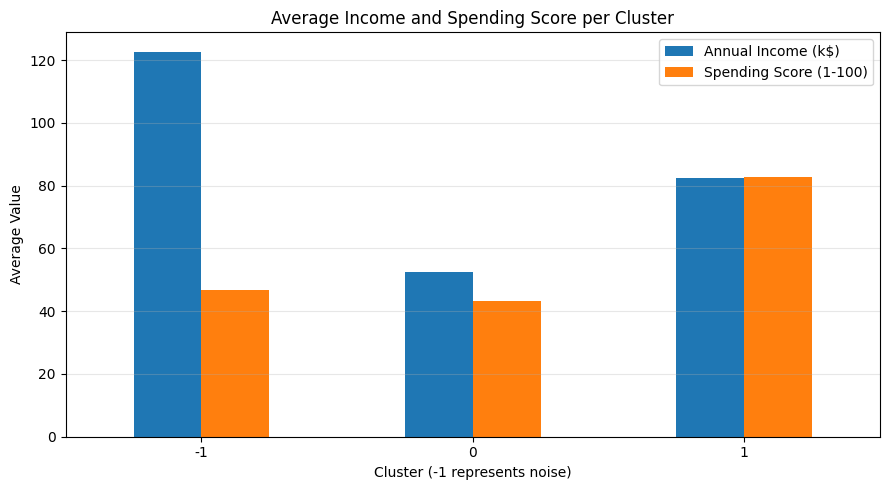

In [ ]:

# Task 6: Analyze Results and Cluster Statistics

# 1. Append cluster labels to the original dataset
df['Cluster'] = labels

print("Customer data with cluster assignments:")
print(df.head(10))

# 2. Calculate mean statistics for each cluster
cluster_stats = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean()

print("\nAverage statistics per cluster:")
print(cluster_stats.round(2))

# 3. Count customers in each cluster
print("\nNumber of customers in each cluster:")
print(df['Cluster'].value_counts().sort_index())

# 4. Analyze noise points (label -1)
noise_data = df[df['Cluster'] == -1]

print("\nNoise Point Analysis:")
print("Number of noise points:", len(noise_data))

if len(noise_data) > 0:
    print("\nAverage statistics of noise points:")
    print(
        noise_data[
            ['Annual Income (k$)', 'Spending Score (1-100)']
        ].mean().round(2)
    )
else:
    print("No noise points detected.")

# 5. Visualize average statistics per cluster
cluster_stats.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Average Income and Spending Score per Cluster')
plt.xlabel('Cluster (-1 represents noise)')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


# Conclusion

The experiment successfully implemented DBSCAN clustering on the Mall Customer Segmentation dataset. Feature standardization ensured balanced neighborhood distance calculations across income and spending metrics. By analyzing $k$-distance graphs, optimal $\varepsilon$ and $min\_samples$ parameters were selected, enabling the discovery of density-defined customer segments and explicit identification of spatial noise points (outliers) without requiring a pre-defined cluster count.